Unknowns: 10000 design variables: 400 L nnz: 49600


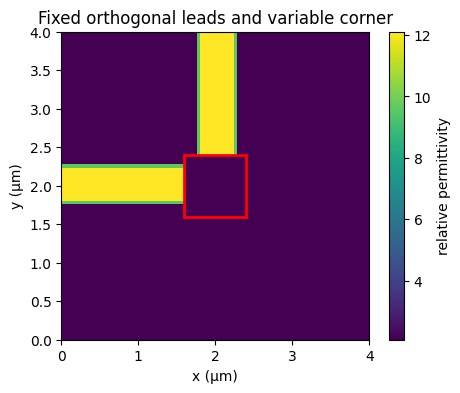

In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.optimize import minimize
import matplotlib.pyplot as plt

nx=ny=100; dx=dy=0.04; npml=10
n_core=3.48; n_clad=1.44; width=0.50; wl0=1.55
N=nx*ny; deps=n_core**2-n_clad**2
x=np.arange(nx)*dx; y=np.arange(ny)*dy
cx=cy=50; source_x=17; input_x=30; output_y=76
ix=np.arange(40,60); jy=np.arange(40,60)
II,JJ=np.meshgrid(ix,jy,indexing='ij'); design_flat=(II*ny+JJ).ravel()
M=design_flat.size; design_shape=II.shape
assert source_x+3<input_x<ix.min()-2
assert jy.max()+3<output_y<ny-npml-3

def subpixel_line(coords,center,h,width):
    overlap=np.maximum(0,np.minimum(coords+h/2,center+width/2)-np.maximum(coords-h/2,center-width/2))
    return n_clad**2+deps*overlap/h

eps_y=subpixel_line(y,y[cy],dy,width)
eps_x=subpixel_line(x,x[cx],dx,width)
# Fixed horizontal lead extends from left to design patch;
# fixed vertical lead extends from design patch upward.
eps_base=np.full((nx,ny),n_clad**2)
eps_base[:ix.min(),:]=eps_y[None,:]
eps_base[:,jy.max()+1:]=np.maximum(eps_base[:,jy.max()+1:],eps_x[:,None])
# The 20x20 design region is *entirely* overwritten by rho.
# At rho=0.5, it is a genuinely nontrivial, partly transmitting corner.

def stretch(n,pml,alpha=4.0,order=3):
    s=np.ones(n,complex)
    for i in range(n):
        d=max(pml-i,i-(n-pml-1),0)
        if d>0: s[i]=1+1j*alpha*(d/pml)**order
    return s
sx=stretch(nx,npml); sy=stretch(ny,npml)
assert np.all(sx[ix]==1) and np.all(sy[jy]==1)

def build_laplacian():
    rows=[];cols=[];vals=[]
    for i in range(nx):
        for j in range(ny):
            p=i*ny+j; diag=0j
            for di,dj,h,s in ((-1,0,dx,sx),(1,0,dx,sx),(0,-1,dy,sy),(0,1,dy,sy)):
                ii,jj=i+di,j+dj; q=i if di else j
                if 0<=ii<nx and 0<=jj<ny:
                    face=0.5*(1/s[q]+1/s[q+(di if di else dj)])
                    coeff=face/(s[q]*h*h)
                    rows.append(p);cols.append(ii*ny+jj);vals.append(coeff)
                else:
                    coeff=1/(s[q]**2*h*h)
                diag-=coeff
            rows.append(p);cols.append(p);vals.append(diag)
    return sp.coo_matrix((vals,(rows,cols)),shape=(N,N)).tocsc()
L=build_laplacian()
print('Unknowns:',N,'design variables:',M,'L nnz:',L.nnz)
plt.figure(figsize=(5,4));plt.imshow(eps_base.T,origin='lower',extent=[0,nx*dx,0,ny*dy],aspect='equal')
plt.gca().add_patch(plt.Rectangle((ix.min()*dx,jy.min()*dy),len(ix)*dx,len(jy)*dy,fill=False,edgecolor='red',lw=2))
plt.title('Fixed orthogonal leads and variable corner');plt.xlabel('x (µm)');plt.ylabel('y (µm)');plt.colorbar(label='relative permittivity');plt.show()

In [2]:
def mode_1d(eps_line,h,k0):
    n=len(eps_line)
    D=sp.diags([np.ones(n-1),-2*np.ones(n),np.ones(n-1)],[-1,0,1],shape=(n,n),format='csr')/h**2
    eig,vec=spla.eigsh(D+k0**2*sp.diags(eps_line),k=1,which='LA')
    beta=np.sqrt(eig[0]); psi=vec[:,0].astype(complex)
    psi/=np.sqrt(np.vdot(psi,psi).real*h)
    kdisc=2*np.arcsin(beta*h/2)/h
    return psi,kdisc,beta

def port_vector(psi,kdisc,h,axis,index,direction='+'):
    # z = c^H E is the forward (+) or backward (-) traveling modal amplitude
    phase=np.exp(1j*kdisc*h); den=phase-1/phase
    if direction=='+': a,b=(-1/phase)/den,1/den
    else: a,b=phase/den,-1/den
    c=np.zeros((nx,ny),complex)
    if axis=='x':
        c[index,:]=np.conj(a)*psi*h; c[index+1,:]=np.conj(b)*psi*h
    else:
        c[:,index]=np.conj(a)*psi*h; c[:,index+1]=np.conj(b)*psi*h
    return c.ravel()

def source(psi,kdisc,axis,index):
    b=np.zeros((nx,ny),complex)
    if axis=='x':
        b[index-1,:]=np.exp(1j*kdisc*x[index])*psi/dx**2
        b[index,:]=-np.exp(1j*kdisc*x[index-1])*psi/dx**2
    else:
        b[:,index-1]=np.exp(1j*kdisc*y[index])*psi/dy**2
        b[:,index]=-np.exp(1j*kdisc*y[index-1])*psi/dy**2
    return b.ravel()

def setup_wavelength(wl):
    k0=2*np.pi/wl
    psi_in,k_in,beta_in=mode_1d(eps_y,dy,k0)
    psi_out,k_out,beta_out=mode_1d(eps_x,dx,k0)
    b=source(psi_in,k_in,'x',source_x)
    cin=port_vector(psi_in,k_in,dy,'x',input_x,'+')
    cback=port_vector(psi_in,k_in,dy,'x',input_x,'-')
    cout=port_vector(psi_out,k_out,dx,'y',output_y,'+')
    # Vertical straight-waveguide reference: source from below and measure upward output.
    eps_ref=np.tile(eps_x[:,None],(1,ny))
    Aref=(L+sp.diags((k0**2*eps_ref).ravel(),format='csc')).tocsc()
    bref=source(psi_out,k_out,'y',source_x)
    Eref=spla.spsolve(Aref,bref)
    pref=float(abs(np.vdot(cout,Eref))**2)
    # Separate horizontal straight-guide calibration for incident amplitude.
    eps_href=np.tile(eps_y[None,:],(nx,1))
    Ahref=(L+sp.diags((k0**2*eps_href).ravel(),format='csc')).tocsc()
    Ehref=spla.spsolve(Ahref,b)
    pin=float(abs(np.vdot(cin,Ehref))**2)
    assert pref>1e-8 and pin>1e-8
    return dict(wl=wl,k0=k0,b=b,cin=cin,cback=cback,cout=cout,pref=pref,pin=pin,
                psi_in=psi_in,psi_out=psi_out,k_in=k_in,k_out=k_out)
ctx=setup_wavelength(wl0)
print('Reference upward output power:',ctx['pref'])
print('Reference horizontal incident power:',ctx['pin'])
print('Input/output effective indices:',ctx['k_in']/ (2*np.pi/wl0),ctx['k_out']/(2*np.pi/wl0),'(discrete k / k0)')

Reference upward output power: 0.9999583795680734
Reference horizontal incident power: 0.9999583795680701
Input/output effective indices: 3.3138327872372226 3.313832787237227 (discrete k / k0)


In [3]:
coords=np.column_stack((II.ravel()*dx,JJ.ravel()*dy))
filter_radius=0.12
D=np.linalg.norm(coords[:,None,:]-coords[None,:,:],axis=2)
weights=np.maximum(0,filter_radius-D)
W=sp.csr_matrix(weights/weights.sum(axis=1,keepdims=True))
eta=0.5

def project(u,beta):
    filt=np.asarray(W@u).ravel()
    den=np.tanh(beta*eta)+np.tanh(beta*(1-eta))
    rho=(np.tanh(beta*eta)+np.tanh(beta*(filt-eta)))/den
    deriv=beta*(1-np.tanh(beta*(filt-eta))**2)/den
    return rho,deriv

def physical_eps(rho):
    eps=eps_base.ravel().copy()
    eps[design_flat]=n_clad**2+deps*np.asarray(rho)
    return eps

def evaluate(u,beta=2.,context=None,with_fields=False):
    context=ctx if context is None else context
    rho,drho=project(u,beta)
    eps=physical_eps(rho)
    A=(L+sp.diags(context['k0']**2*eps,format='csc')).tocsc()
    lu=spla.splu(A)
    E=lu.solve(context['b'])
    z=np.vdot(context['cout'],E)
    T=float(abs(z)**2/context['pref'])
    lam=lu.solve(context['cout']*z/context['pref'],trans='H')
    grho=-2*context['k0']**2*deps*np.real(np.conj(lam[design_flat])*E[design_flat])
    grad=np.asarray(W.T@(grho*drho)).ravel()
    if with_fields:
        back=abs(np.vdot(context['cback'],E))**2/context['pin']
        res=np.linalg.norm(A@E-context['b'])/np.linalg.norm(context['b'])
        return T,grad,E.reshape(nx,ny),rho,float(back),res
    return T,grad

u0=np.full(M,0.5)
T0,g0,E0,rho0,R0,res0=evaluate(u0,with_fields=True)
print('Initial bend T:',T0,'R estimate:',R0,'residual:',res0)
print('Gradient norm:',np.linalg.norm(g0))

Initial bend T: 0.021286156348727454 R estimate: 0.05151723395953624 residual: 7.953074809432718e-15
Gradient norm: 0.08072631216386132


In [4]:
rng=np.random.default_rng(2026)
v=rng.normal(size=M);v/=np.linalg.norm(v)
for h in (1e-2,1e-3,1e-4):
    Tp=evaluate(u0+h*v)[0];Tm=evaluate(u0-h*v)[0]
    fd=(Tp-Tm)/(2*h); adj=np.dot(g0,v)
    rel=abs(fd-adj)/max(abs(fd),abs(adj),1e-12)
    print(f'h={h:.0e}: FD={fd:.9e} adj={adj:.9e} rel={rel:.3e}')
assert np.isfinite(T0) and np.all(np.isfinite(g0))

h=1e-02: FD=-7.358778786e-03 adj=-7.358781826e-03 rel=4.130e-07
h=1e-03: FD=-7.358781795e-03 adj=-7.358781826e-03 rel=4.125e-09
h=1e-04: FD=-7.358781825e-03 adj=-7.358781826e-03 rel=1.261e-10


In [5]:
projection_schedule=(2.0,5.0)
maxiter_per_stage=8  # CPU-friendly starting point; increase to 20+ for research runs
u=u0.copy(); history=[T0]; stage_reports=[]
for beta in projection_schedule:
    print('\nProjection beta:',beta)
    cache={'u':None,'result':None}
    def f_and_g(z):
        if cache['u'] is None or not np.array_equal(z,cache['u']):
            cache['u']=z.copy();cache['result']=evaluate(z,beta)
        T,g=cache['result']
        return -T,-g
    def callback(z):
        T=evaluate(z,beta)[0];history.append(T)
        print(f'  accepted {len(history)-1:02d}: T={T:.8f}')
    result=minimize(f_and_g,u,method='L-BFGS-B',jac=True,bounds=[(0.,1.)]*M,
                    callback=callback,options={'maxiter':maxiter_per_stage,'ftol':1e-11,'gtol':1e-6})
    u=result.x.copy();stage_reports.append((beta,result.success,result.message,result.nit))
    print('termination:',result.message,'iterations:',result.nit)
Topt,gopt,Eopt,rhoopt,Ropt,resopt=evaluate(u,projection_schedule[-1],with_fields=True)
rho_binary=(rhoopt>=0.5).astype(float)
print('Initial/optimized T:',T0,Topt,'reflection estimates:',R0,Ropt)
print('Optimized residual:',resopt,'intermediate fraction:',np.mean((rhoopt>.05)&(rhoopt<.95)))
print('Stage reports:',stage_reports)


Projection beta: 2.0
  accepted 01: T=0.02828384
  accepted 02: T=0.53158806
  accepted 03: T=0.73103248
  accepted 04: T=0.80370562
  accepted 05: T=0.83654077
  accepted 06: T=0.84808328
  accepted 07: T=0.85757160
  accepted 08: T=0.86432754
termination: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT iterations: 8

Projection beta: 5.0
  accepted 09: T=0.89636977
  accepted 10: T=0.90248489
  accepted 11: T=0.90368203
  accepted 12: T=0.90618451
  accepted 13: T=0.90864022
  accepted 14: T=0.91343787
  accepted 15: T=0.91554868
  accepted 16: T=0.92145094
termination: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT iterations: 8
Initial/optimized T: 0.021286156348727454 0.921450938571124 reflection estimates: 0.05151723395953624 0.0010860974604397647
Optimized residual: 8.069346454235164e-15 intermediate fraction: 0.3625
Stage reports: [(2.0, False, 'STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT', 8), (5.0, False, 'STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT', 8)]


Initial: T=0.021286 R~=0.051517
Continuous: T=0.921451 R~=0.001086
Binary: T=0.929246 R~=0.002401


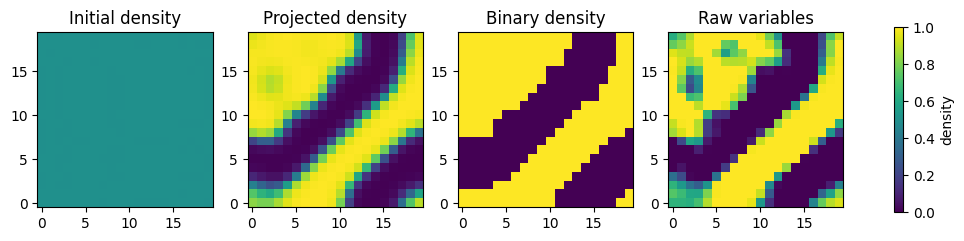

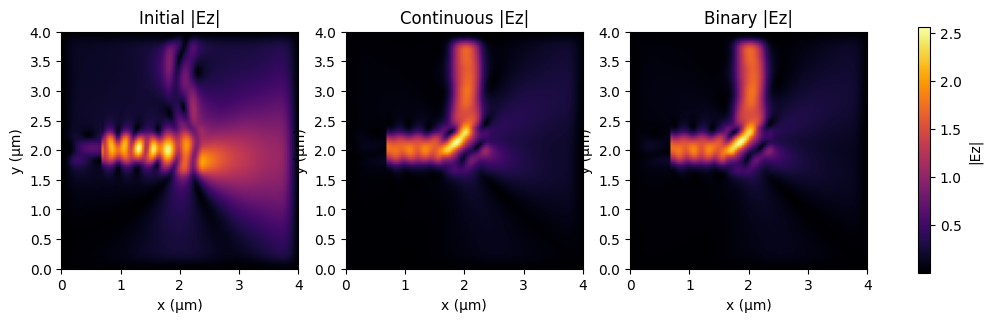

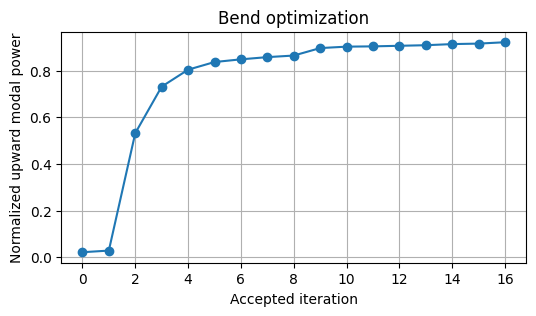

In [6]:
def evaluate_rho(rho,context=ctx,fields=False):
    A=(L+sp.diags(context['k0']**2*physical_eps(rho),format='csc')).tocsc()
    E=spla.spsolve(A,context['b'])
    T=float(abs(np.vdot(context['cout'],E))**2/context['pref'])
    R=float(abs(np.vdot(context['cback'],E))**2/context['pin'])
    if fields:return T,R,E.reshape(nx,ny)
    return T,R
Tb,Rb,Eb=evaluate_rho(rho_binary,fields=True)
print(f'Initial: T={T0:.6f} R~={R0:.6f}')
print(f'Continuous: T={Topt:.6f} R~={Ropt:.6f}')
print(f'Binary: T={Tb:.6f} R~={Rb:.6f}')
fig,axs=plt.subplots(1,4,figsize=(13,3))
for ax,r,title in zip(axs,[rho0,rhoopt,rho_binary,u],['Initial density','Projected density','Binary density','Raw variables']):
    im=ax.imshow(r.reshape(design_shape).T,origin='lower',vmin=0,vmax=1,cmap='viridis');ax.set_title(title)
fig.colorbar(im,ax=axs.ravel().tolist(),shrink=.8,label='density');plt.show()
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,E,title in zip(axs,[E0,Eopt,Eb],['Initial |Ez|','Continuous |Ez|','Binary |Ez|']):
    im=ax.imshow(abs(E).T,origin='lower',extent=[0,nx*dx,0,ny*dy],cmap='inferno')
    ax.set_title(title);ax.set(xlabel='x (µm)',ylabel='y (µm)')
fig.colorbar(im,ax=axs.ravel().tolist(),shrink=.8,label='|Ez|');plt.show()
plt.figure(figsize=(6,3));plt.plot(history,'o-');plt.xlabel('Accepted iteration');plt.ylabel('Normalized upward modal power');plt.title('Bend optimization');plt.grid();plt.show()

1.50 µm: initial T=0.012919, continuous T=0.928143, binary T=0.932771, binary R~=0.001050
1.55 µm: initial T=0.021286, continuous T=0.921451, binary T=0.929246, binary R~=0.002401
1.60 µm: initial T=0.031600, continuous T=0.906560, binary T=0.920950, binary R~=0.001877


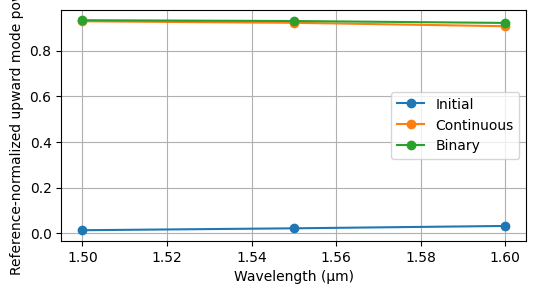

In [7]:
wavelengths=(1.50,1.55,1.60)
sweep=[]
for wl in wavelengths:
    c=ctx if wl==wl0 else setup_wavelength(wl)
    initial=evaluate_rho(rho0,c)
    continuous=evaluate_rho(rhoopt,c)
    binary=evaluate_rho(rho_binary,c)
    sweep.append((wl,initial[0],continuous[0],binary[0],binary[1]))
    print(f'{wl:.2f} µm: initial T={initial[0]:.6f}, continuous T={continuous[0]:.6f}, binary T={binary[0]:.6f}, binary R~={binary[1]:.6f}')
sweep=np.array(sweep)
plt.figure(figsize=(6,3));
for k,label in ((1,'Initial'),(2,'Continuous'),(3,'Binary')):plt.plot(sweep[:,0],sweep[:,k],'o-',label=label)
plt.xlabel('Wavelength (µm)');plt.ylabel('Reference-normalized upward mode power');plt.legend();plt.grid();plt.show()

In [8]:
fgrad=-gopt
pg=u-np.clip(u-fgrad,0,1)
print('Projected-gradient infinity norm:',np.max(np.abs(pg)))
print('Final continuous objective:',Topt,'binary objective:',Tb)
print('Stage success flags:',[s[1] for s in stage_reports])
np.savez('notebook08_bend_results.npz',u=u,rho_initial=rho0,rho_continuous=rhoopt,
         rho_binary=rho_binary,history=np.asarray(history),sweep=sweep,
         T_initial=T0,T_continuous=Topt,T_binary=Tb,R_initial=R0,R_continuous=Ropt,R_binary=Rb)
print('Saved notebook08_bend_results.npz')

Projected-gradient infinity norm: 0.0028424183677098203
Final continuous objective: 0.921450938571124 binary objective: 0.9292460959180336
Stage success flags: [False, False]
Saved notebook08_bend_results.npz
